# BNPL Credit Risk — Modelling

**This is the local version** (Jupyter on your own computer). It reads the data from the same folder as the notebook, and it is saved with all outputs printed. A Google Colab version is `BNPL_CreditRisk_Modeling_Colab.ipynb`.

**Goal:** build models that predict whether a Buy Now Pay Later customer will **default**, compare them, and report how well they work.

This notebook continues from the EDA notebook (`BNPL_CreditRisk_EDA.ipynb`). Every decision about which columns to use and how to transform them comes from the EDA findings.

**What we do, in order:**

| Step | Section |
|---|---|
| Learn the modelling basics | 0 |
| Set up and load the data | 1–2 |
| Choose features, using the EDA findings | 3 |
| Feature engineering (creating new, more useful columns) | 4 |
| Check that features don't overlap too much | 5 |
| Split into training and test data | 6 |
| Prepare the data for the models (scaling, encoding) | 7 |
| Set benchmarks to beat | 8 |
| Model 1: Logistic regression | 9 |
| Model 2: Decision tree | 10 |
| Model 3: Random forest | 11 |
| Compare all models on every metric | 12 |
| Choose a cut-off (approve / decline threshold) | 13 |
| Rank customers into risk groups (gains table) | 14 |
| Which features matter most? | 15 |
| Summary and conclusions | 16 |

> **How to read this notebook:** before every code cell, a text cell explains **what we are doing and why** and **how the code works**. After important outputs, a **"What we see"** note explains the result in plain English.

## 0. Modelling basics

Read this section once before running anything. It explains every idea used later.

### 0.1 What is a model?

A **model** is a formula or a set of rules that takes a customer's details (the **features**) and outputs a prediction (here: the **probability of default**).

We don't write the rules ourselves. We give the model thousands of **past customers whose outcome we already know**, and it **learns** the rules that best separate defaulters from non-defaulters. This is called **training** (or **fitting**) the model.

Because the outcome is a category (default yes/no), this is a **classification** problem. All three models we use output a **probability** between 0 and 1. To make an approve/decline decision we compare that probability with a **cut-off** (or **threshold**), usually 0.5 by default: probability above the cut-off → predict "default".

### 0.2 Training data vs test data

If we test a model on the same customers it learned from, it will look better than it really is. It's like a student who memorised the answers to last year's exam: perfect score, but no proof they understand the subject.

So we **split** the data:
- **Training set (70%):** the model learns from these customers.
- **Test set (30%):** kept aside and used **only once, at the end**, to measure performance on customers the model has never seen. This simulates new applicants.

### 0.3 Overfitting and underfitting

- **Overfitting:** the model learns the training data *too* well, including random noise and coincidences. It scores brilliantly on training data and noticeably worse on test data. Common with very deep decision trees.
- **Underfitting:** the model is too simple to capture real patterns. It scores poorly on both.
- **Healthy model:** training and test scores are close, and both are good.

We always compare training and test scores to detect overfitting.

### 0.4 The three models

**1. Logistic regression.** The classic credit-scoring model, used by banks for decades.
- It gives each feature a **weight** (coefficient). It adds up `weight × feature value` for all features, and converts the total into a probability between 0 and 1 using the S-shaped **logistic function**.
- The total it adds up is the **log-odds** of default. **Odds** = probability of default ÷ probability of no default (e.g. 20% vs 80% gives odds of 0.25, or "1 to 4"). This is the same odds concept used in betting.
- **Strengths:** simple, fast, very easy to explain ("each missed payment multiplies the odds of default by 1.5"). Regulators like it. It converts directly into a points-based **scorecard**.
- **Weakness:** it assumes each feature pushes risk steadily up or down (a straight line on the log-odds scale). It can't natively capture a "cliff" like the credit score effect at 600 that we found in the EDA. **Feature engineering** (Section 4) fixes this.

**2. Decision tree.** A flowchart of yes/no questions, exactly like a credit policy rulebook.
- Example: "Is credit score above 600? → If yes, is DTI below 10%? → If yes: low risk."
- The tree learns which questions to ask, in which order, and where to put the cut-offs, by repeatedly choosing the split that best separates defaulters from non-defaulters.
- **Strengths:** very easy to explain and draw. Handles cliffs and interactions naturally. No scaling needed.
- **Weakness:** a deep tree overfits badly (it keeps splitting until it memorises individual customers). We limit its depth.

**3. Random forest.** A **committee of hundreds of decision trees**.
- Each tree is trained on a random sample of customers and only sees a random subset of features at each split. The final prediction is the **average** of all the trees' predictions.
- It's like **diversification** in a portfolio: individual trees make different mistakes, and averaging cancels out much of the noise.
- **Strengths:** usually more accurate and more stable than a single tree. Less overfitting.
- **Weakness:** a "black box". You can't draw 300 trees, so it's harder to explain an individual decision.

### 0.5 Hyperparameters and cross-validation

**Parameters** are learned from the data (e.g. logistic regression weights). **Hyperparameters** are settings *we* choose before training, e.g. the maximum depth of a tree or the number of trees in a forest.

To choose hyperparameters without touching the test set, we use **cross-validation (CV)** on the training set:
1. Split the training data into 5 equal parts ("folds").
2. Train on 4 folds, measure performance on the 5th.
3. Repeat 5 times so each fold is used once for measuring.
4. Average the 5 scores.

**Grid search** tries every combination of hyperparameters from a list we provide, runs cross-validation for each, and picks the best combination. The test set stays untouched until the final evaluation.

### 0.6 How we measure a model: the confusion matrix

With a cut-off, every test customer lands in one of four boxes:

| | **Predicted: default** (decline) | **Predicted: no default** (approve) |
|---|---|---|
| **Actually defaulted** | **True Positive (TP)**: correctly declined a bad customer | **False Negative (FN)**: approved a bad customer → **credit loss** |
| **Actually repaid** | **False Positive (FP)**: declined a good customer → **lost revenue** | **True Negative (TN)**: correctly approved a good customer |

"Positive" here means "default", the event we're trying to catch. In credit risk, **a false negative is usually more expensive than a false positive**: a bad loan loses the whole amount, while a wrongly declined customer only loses the margin you would have earned.

### 0.7 The metrics we report

**Threshold-based metrics** (depend on the cut-off, 0.5 unless stated):

| Metric | Formula | Plain English | Credit meaning |
|---|---|---|---|
| **Accuracy** | (TP + TN) ÷ all | Share of all predictions that are correct | Misleading if defaults are rare |
| **Precision** | TP ÷ (TP + FP) | Of the customers we flagged as risky, how many really defaulted? | Low precision = declining many good customers |
| **Recall** (sensitivity, TPR) | TP ÷ (TP + FN) | Of the customers who really defaulted, how many did we catch? | Low recall = approving bad customers = losses |
| **Specificity** (TNR) | TN ÷ (TN + FP) | Of the good customers, how many did we approve? | Customer experience for good customers |
| **F1 score** | 2 × P × R ÷ (P + R) | Balance between precision and recall | Single summary when both matter |
| **Balanced accuracy** | (Recall + Specificity) ÷ 2 | Accuracy that treats both classes equally | Robust to class imbalance |

**Ranking metrics** (don't depend on the cut-off; they measure how well the model *orders* customers from riskiest to safest):

| Metric | Range | Plain English |
|---|---|---|
| **ROC AUC** | 0.5 (random) → 1.0 (perfect) | Pick one random defaulter and one random good customer. AUC is the probability the model gives the defaulter a higher risk score. **The main metric in credit scoring.** |
| **Gini** | 0 → 1 | = 2 × AUC − 1. The same information on a different scale; this is the number banks usually quote. A Gini of 0.4–0.6 is typical for application scorecards. |
| **KS statistic** | 0 → 1 | The biggest gap between the share of defaulters and the share of good customers captured below any score cut-off. Another banking standard; 0.3–0.5 is usually considered good. |
| **PR AUC** (average precision) | base rate → 1.0 | Area under the precision-recall curve. Focuses only on how well we find defaulters. A random model scores the default rate (here ~0.39). |

**Probability-quality metrics** (are the predicted probabilities realistic?):

| Metric | Better | Plain English |
|---|---|---|
| **Log loss** | Lower | Heavily penalises confident wrong predictions (e.g. saying 1% default risk for someone who defaults). |
| **Brier score** | Lower | Average squared difference between predicted probability and the actual outcome (0 or 1). 0 is perfect. |

Probability quality matters in lending because probabilities feed directly into **pricing** and **expected loss** (Expected Loss = Probability of Default × Exposure × Loss Given Default).

## 1. Setup

### 1.1 Locate the data file

#### What we're doing
Telling the notebook where the CSV file is. In this local version, the file must be in the **same folder as the notebook**.

#### How the code works
- `DATA_PATH` holds the file name. Because no folder is given, Python looks in the notebook's own folder.
- `os.path.exists(DATA_PATH)` checks the file is really there and prints a clear message if not. If it's missing, either move the CSV next to the notebook, or change `DATA_PATH` to the full path, e.g. `"/Users/yourname/Downloads/Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv"`.

In [1]:
import os

DATA_PATH = "Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv"

if os.path.exists(DATA_PATH):
    print("Found the dataset:", DATA_PATH)
else:
    print("Dataset NOT found at:", os.path.abspath(DATA_PATH))
    print("Move the CSV into the same folder as this notebook, or change DATA_PATH.")

Found the dataset: Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv


### 1.2 Load the libraries

#### What we're doing
Loading the toolkits we need. Besides `pandas`, `numpy` and `matplotlib` (used in the EDA), we now use **scikit-learn** (`sklearn`), the standard Python library for machine learning. It provides the models, the train/test split, cross-validation and all the metrics. If any import fails with `ModuleNotFoundError`, run `pip install pandas matplotlib scikit-learn` in a terminal.

#### How the code works
- `from sklearn.xxx import Yyy` loads one specific tool from scikit-learn. Each line is grouped by purpose: splitting data, preparing features, models, and metrics.
- `RANDOM_STATE = 42` fixes the "random seed". Several steps involve randomness (the train/test split, the random forest). Fixing the seed means **you get exactly the same results every time** you run the notebook. 42 is just a convention; any number works.
- The chart style and colours match the EDA notebook.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Splitting data and tuning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score

# Preparing features
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve, classification_report,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)

# ---- Chart style (same as the EDA notebook) ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODEL_COLOURS = {"Logistic regression": BLUE, "Decision tree": ORANGE, "Random forest": AQUA}

plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "font.size": 10, "lines.linewidth": 2,
})
print("Libraries loaded.")

Libraries loaded.


## 2. Load the data

#### What we're doing
Reading the CSV into a pandas table (`df`) and confirming its size and the overall default rate match what we saw in the EDA (10,345 customers, 39% default rate).

#### How the code works
- `pd.read_csv(DATA_PATH)` reads the file.
- `df["default_flag"].mean()` is the default rate (the average of a 0/1 column is the share of 1s).

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Overall default rate: {df['default_flag'].mean():.1%}")
df.head()

Rows: 10,345   Columns: 17
Overall default rate: 39.1%


,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
0,1,56,Salaried,"68,529.5000",552,"5,000.0000",Electronics,12,13,1,0,8.4900,Australia,2023-06-10,0.0730,165.2000,Medium Risk
1,2,19,Student,"7,247.8500",300,"1,073.2300",Fashion,12,13,1,0,3.0900,USA,2024-10-07,0.1481,266.0000,High Risk
2,3,20,Self-Employed,"41,582.2600",471,"5,000.0000",Electronics,3,19,2,0,3.3300,Australia,2023-04-05,0.1202,229.6000,High Risk
3,4,21,Salaried,"14,423.4600",300,"4,076.8300",Sports,6,18,5,1,5.8600,Germany,2023-06-24,0.2827,356.0000,High Risk
4,5,43,Salaried,"42,845.5000",512,"5,000.0000",Electronics,9,0,0,0,7.3600,India,2024-10-19,0.1167,135.2000,High Risk


## 3. Choosing the features (based on the EDA)

#### What we're doing
Deciding which columns go into the model. A good feature set is **predictive** (it helps separate good and bad customers), **available at decision time** (no leakage), and **not redundant**. Dropping useless columns makes the model simpler, easier to explain, and less likely to learn noise.

Every decision below comes from a specific EDA finding:

| Column | Decision | Reason (EDA section) |
|---|---|---|
| `credit_score` | **Keep** | Strongest predictor; IV 0.73; sharp cliff at 600 (6.1, 10) |
| `monthly_income` | **Keep, as log** | Strong (IV 0.48), but right-skewed and 0.96 correlated with credit score (6.3, 8) |
| `debt_to_income_ratio` | **Keep** | Strong (IV 0.33); default doubles above 10% (6.4) |
| `missed_payments` | **Keep** | Strong (IV 0.42); treated as *past* history, not leakage (6.5) |
| `repayment_delay_days` | **Keep** | Strong (IV 0.50); treated as *past* history, not leakage (6.5) |
| `employment_type` | **Keep** | Medium (IV 0.17) (6.2, 9) |
| `age` | **Keep** | Weak (IV 0.03), but cheap to include; we check whether it helps |
| `user_id` | Drop | Just an identifier, carries no information |
| `risk_score` | Drop (**benchmark only**) | Exact formula of credit score, missed payments and delay (7.2) |
| `customer_segment` | Drop | Mostly credit-score bands (7.3) |
| `purchase_amount` | Drop | Capped at 5,000 for 59% of customers; its useful part is already in DTI (3, 6.7, 7.1) |
| `product_category` | Drop | No relationship with default; IV 0.00 (6.7) |
| `location` | Drop | No relationship with default; IV 0.00 (6.7) |
| `bnpl_installments` | Drop | No relationship with default; IV 0.00 (6.7) |
| `app_usage_frequency` | Drop | No relationship with default; IV 0.00 (6.7) |
| `transaction_date` | Drop | Default rate is flat over time (6.7) |

#### How the code works
- `DROP_COLUMNS` is a Python **dictionary**: each column name (the "key") is paired with the reason (the "value").
- `df.drop(columns=...)` returns a copy of the table without those columns. We keep the original `df` untouched (we still need `risk_score` for the benchmark).

In [4]:
DROP_COLUMNS = {
    "user_id": "identifier",
    "risk_score": "derived formula (used only as a benchmark)",
    "customer_segment": "derived from credit score",
    "purchase_amount": "capped at 5,000; information already in DTI",
    "product_category": "no relationship with default",
    "location": "no relationship with default",
    "bnpl_installments": "no relationship with default",
    "app_usage_frequency": "no relationship with default",
    "transaction_date": "default rate flat over time",
}

model_df = df.drop(columns=list(DROP_COLUMNS))
print("Columns kept:", list(model_df.columns))

Columns kept: ['age', 'employment_type', 'monthly_income', 'credit_score', 'repayment_delay_days', 'missed_payments', 'default_flag', 'debt_to_income_ratio']


## 4. Feature engineering

**Feature engineering** means creating new columns that make patterns easier for a model to learn. It often improves a model more than switching to a fancier algorithm.

#### What we're doing and why

**1. Log of income.** Income is right-skewed: a few very high earners stretch the scale. Taking the **logarithm** compresses large values, so the difference between 5,000 and 10,000 counts as much as between 50,000 and 100,000 (both are a doubling). That matches reality: an extra 5,000 matters far more to a low earner. It also stops a few extreme incomes from dominating the logistic regression.

**2. Threshold flags.** The EDA found several **cliff-shaped** effects: risk is flat, then suddenly jumps or drops. Logistic regression can only draw straight lines (on the log-odds scale), so it can't capture a cliff by itself. We give it a helping hand by adding 0/1 **flag** columns at exactly the cliffs we found:

| New feature | Rule | EDA finding |
|---|---|---|
| `no_credit_history` | credit score = 300 | 58% default at exactly 300 (likely "no file" customers) |
| `score_above_600` | credit score > 600 | Default falls from ~30–49% to ~6% above 600 |
| `missed_3plus` | missed payments ≥ 3 | Default jumps above 80% at 3+ missed payments |
| `delay_over_15` | delay > 15 days | Default jumps from ~36% to 73%+ beyond 15 days |
| `dti_over_10pct` | DTI > 0.10 | Default roughly doubles above 10% |

Decision trees and random forests find cliffs on their own, so the flags matter most for logistic regression. We give **all three models the same features**, so the comparison is fair.

#### How the code works
- `np.log(...)` takes the natural logarithm of every value in the column. Incomes are all at least 5,000, so there are no zeros (the log of 0 is undefined).
- `(model_df["credit_score"] == 300)` gives True/False per row; `.astype(int)` turns True/False into 1/0.
- At the end, we check each flag's default rate when it's 1 vs 0, to confirm the flags capture the cliffs we expect.

In [5]:
model_df["log_income"] = np.log(model_df["monthly_income"])

model_df["no_credit_history"] = (model_df["credit_score"] == 300).astype(int)
model_df["score_above_600"]   = (model_df["credit_score"] > 600).astype(int)
model_df["missed_3plus"]      = (model_df["missed_payments"] >= 3).astype(int)
model_df["delay_over_15"]     = (model_df["repayment_delay_days"] > 15).astype(int)
model_df["dti_over_10pct"]    = (model_df["debt_to_income_ratio"] > 0.10).astype(int)

FLAGS = ["no_credit_history", "score_above_600", "missed_3plus", "delay_over_15", "dti_over_10pct"]

check = pd.DataFrame({
    "customers with flag = 1": [model_df[f].sum() for f in FLAGS],
    "default rate if 0": [model_df.loc[model_df[f] == 0, "default_flag"].mean() for f in FLAGS],
    "default rate if 1": [model_df.loc[model_df[f] == 1, "default_flag"].mean() for f in FLAGS],
}, index=FLAGS)
check.style.format({"customers with flag = 1": "{:,}", "default rate if 0": "{:.1%}", "default rate if 1": "{:.1%}"})

,customers with flag = 1,default rate if 0,default rate if 1
no_credit_history,"1,373",36.1%,58.3%
score_above_600,"1,729",45.6%,6.7%
missed_3plus,835,35.2%,83.1%
delay_over_15,"1,933",31.2%,73.2%
dti_over_10pct,"6,559",23.7%,47.9%


**What we see:** every flag splits customers into two groups with very different default rates, exactly as the EDA predicted:
- `missed_3plus`: 83% default when the flag is 1, against 35% when it's 0.
- `delay_over_15`: 73% against 31%.
- `score_above_600`: only 7% default above 600, against 46% below.
- `no_credit_history`: 58% at a score of 300, against 36% otherwise.
- `dti_over_10pct`: 48% against 24%. Note that this flag is 1 for most customers (6,559 of 10,345).

#### Final feature list

#### What we're doing
Writing down the exact features the models will use, split by type, because numeric and categorical columns need different preparation (Section 7).

- **Numeric:** the original numeric features, with `log_income` replacing `monthly_income`, plus the five flags.
- **Categorical:** `employment_type`.
- **Target:** `default_flag`.

In [6]:
NUMERIC_FEATURES = ["credit_score", "log_income", "debt_to_income_ratio",
                    "missed_payments", "repayment_delay_days", "age"] + FLAGS
CATEGORICAL_FEATURES = ["employment_type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "default_flag"

print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {len(FEATURES)} features")
print("Numeric:", NUMERIC_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)

11 numeric + 1 categorical = 12 features
Numeric: ['credit_score', 'log_income', 'debt_to_income_ratio', 'missed_payments', 'repayment_delay_days', 'age', 'no_credit_history', 'score_above_600', 'missed_3plus', 'delay_over_15', 'dti_over_10pct']
Categorical: ['employment_type']


## 5. Checking for multicollinearity (VIF)

#### What we're doing
In the EDA, income and credit score had a correlation of 0.96, almost the same information. When two features overlap that much, logistic regression struggles to decide how much weight to give each one. The **total** prediction is still fine, but the **individual coefficients** become unstable and hard to interpret (one might even get the "wrong" sign).

The standard check is the **Variance Inflation Factor (VIF)**. For each feature, we try to predict it from all the *other* features using linear regression:
- **VIF = 1 ÷ (1 − R²)**, where R² is how well the other features predict it (0 = not at all, 1 = perfectly).
- **VIF around 1:** the feature is independent of the others.
- **VIF above 5:** worth watching. **Above 10:** serious overlap.

#### How the code works
- `vif(...)` loops over the numeric features. For each one, it fits a linear regression (`np.linalg.lstsq`) predicting it from the others plus a constant, computes R², then VIF.
- We only check the main numeric features. The flags are, by design, derived from them, so they would naturally show some overlap.

In [7]:
def vif(data, columns):
    out = {}
    for col in columns:
        y = data[col].values
        X = np.column_stack([data[[c for c in columns if c != col]].values, np.ones(len(data))])
        coef, *_ = np.linalg.lstsq(X, y, rcond=None)
        r2 = 1 - ((y - X @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[col] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False).to_frame()

vif(model_df, ["credit_score", "log_income", "debt_to_income_ratio", "missed_payments",
               "repayment_delay_days", "age"])

,VIF
log_income,6.6923
credit_score,6.0489
missed_payments,2.2196
debt_to_income_ratio,2.1547
repayment_delay_days,2.0393
age,1.0427


**What we see:**
- `log_income` (VIF 6.7) and `credit_score` (6.0) overlap heavily, as expected from their 0.96 correlation in the EDA. Both are above the "worth watching" level of 5, but below the "serious" level of 10.
- All other features are below 2.3, so they are fairly independent.

**Decision:** we keep both. Together they predict well, and dropping one would lose a little information. But we must **not over-interpret their individual logistic regression coefficients** (Section 9.1). Trees are not affected by this issue.

## 6. Splitting into training and test sets

#### What we're doing
Setting aside **30% of customers as the test set**, which we won't look at until the final evaluation (Section 12). The models learn from the other 70%.

We use a **stratified** split: both sets get the same default rate (39%). Without stratification, random chance could give one set noticeably more defaulters, which would distort the comparison.

#### How the code works
- `X` holds the features, `y` the target. This naming is a universal convention in machine learning.
- `train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)`:
  - `test_size=0.30` puts 30% of rows in the test set.
  - `stratify=y` keeps the default rate equal in both sets.
  - `random_state` makes the split identical every time you run it.
- It returns four objects: training features, test features, training target, test target.

In [8]:
X = model_df[FEATURES]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {len(X_train):,} customers, default rate {y_train.mean():.1%}")
print(f"Test set:     {len(X_test):,} customers, default rate {y_test.mean():.1%}")

Training set: 7,241 customers, default rate 39.1%
Test set:     3,104 customers, default rate 39.0%


**What we see:** 7,241 training and 3,104 test customers, with almost identical default rates (39.1% and 39.0%), thanks to stratification.

## 7. Preparing the data for the models (preprocessing)

#### What we're doing
Models need all inputs as numbers on comparable scales. Two transformations:

**1. Scaling numeric features (standardisation), for logistic regression only.** Credit score runs from 300 to 850, while DTI runs from 0 to 0.7. Logistic regression is sensitive to these different scales: the penalty that stops it overfitting (called **regularisation**) treats all coefficients alike, so features on larger scales get treated unfairly. **Standardising** converts every numeric feature to have **mean 0 and standard deviation 1**:

`scaled value = (value − mean) ÷ standard deviation`

A scaled value of +2 means "2 standard deviations above the average customer".

**Trees don't need scaling**: they only ask "is this value above or below a cut-off?", and scaling doesn't change which customers fall on which side. So for the decision tree and random forest we **leave the values unchanged**. Bonus: the tree diagram in Section 10.2 then shows real values, like `credit_score <= 600`, instead of standardised ones.

**2. One-hot encoding the categorical feature.** Models can't do maths on text like "Student". One-hot encoding turns one text column into several 0/1 columns, one per category:

| employment_type | is_Self-Employed | is_Student | is_Unemployed |
|---|---|---|---|
| Salaried | 0 | 0 | 0 |
| Self-Employed | 1 | 0 | 0 |
| Student | 0 | 1 | 0 |
| Unemployed | 0 | 0 | 1 |

We drop one category (`drop="first"`, here **Salaried**, first alphabetically). It becomes the **reference category**: the others are measured relative to it. Keeping all four would be redundant, because the fourth column can always be worked out from the other three.

**Avoiding leakage in preprocessing.** The mean and standard deviation for scaling must be computed from the **training set only**, then applied to the test set. If we computed them on all data, a little information about the test customers would leak into training. A scikit-learn **Pipeline** handles this automatically: it learns the scaling from whatever data it's trained on.

#### How the code works
- `ColumnTransformer` applies different preparation to different columns: `StandardScaler()` (or `"passthrough"`, meaning "leave unchanged") to the numeric list, `OneHotEncoder(drop="first")` to the categorical list.
- `make_preprocessor(scale=True)` builds that preparation step; `scale=False` skips scaling (used for the trees).
- `make_pipeline(model, scale=True)` is a small helper that chains this preparation and a model into one object. Calling `.fit(X_train, y_train)` on the pipeline learns the scaling *and* trains the model in one step. Calling `.predict_proba(X_test)` applies the *same* scaling to new data, then predicts.
- `preprocessor.fit(X_train)` here is only for display: it shows the column names after encoding.

In [9]:
def make_preprocessor(scale=True):
    numeric_step = StandardScaler() if scale else "passthrough"   # "passthrough" = leave values unchanged
    return ColumnTransformer([
        ("numeric", numeric_step, NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(drop="first"), CATEGORICAL_FEATURES),
    ])

def make_pipeline(model, scale=True):
    return Pipeline([("prep", make_preprocessor(scale)), ("model", model)])

preprocessor = make_preprocessor()

feature_names = (preprocessor.fit(X_train).get_feature_names_out())
feature_names = [n.split("__", 1)[1] for n in feature_names]   # drop the "numeric__" prefix
print(f"{len(feature_names)} model inputs after encoding:")
print(feature_names)

14 model inputs after encoding:
['credit_score', 'log_income', 'debt_to_income_ratio', 'missed_payments', 'repayment_delay_days', 'age', 'no_credit_history', 'score_above_600', 'missed_3plus', 'delay_over_15', 'dti_over_10pct', 'employment_type_Self-Employed', 'employment_type_Student', 'employment_type_Unemployed']


## 8. Benchmarks: what do we need to beat?

#### What we're doing
A model is only useful if it beats simple alternatives. We set two benchmarks on the test set:

1. **The naive model:** predict "no default" for everyone. Its accuracy equals the share of good customers (~61%). Any model with lower accuracy is worse than doing nothing. Its AUC is 0.5, the same as random guessing, because it can't rank customers at all.
2. **The existing `risk_score`:** the rule-based score in the dataset (340 − 0.4 × credit score + 20 × missed payments + 2 × delay days). We use it directly as a risk ranking and measure its AUC. Our models should beat this; otherwise, the simple rule would be good enough.

#### How the code works
- `np.zeros(len(y_test))` creates a prediction of 0 ("no default") for every test customer.
- `roc_auc_score(y_true, scores)` works with any score where higher = riskier, so we can pass `risk_score` directly.
- `df.loc[X_test.index, "risk_score"]` picks the `risk_score` of exactly the test customers (the split kept the original row numbers, called the **index**).

In [10]:
naive_accuracy = accuracy_score(y_test, np.zeros(len(y_test)))
risk_score_test = df.loc[X_test.index, "risk_score"]
risk_score_auc = roc_auc_score(y_test, risk_score_test)

print(f"Naive model ('nobody defaults'): accuracy {naive_accuracy:.1%}, AUC 0.500")
print(f"Existing risk_score:             AUC {risk_score_auc:.3f}, Gini {2 * risk_score_auc - 1:.3f}")

Naive model ('nobody defaults'): accuracy 61.0%, AUC 0.500
Existing risk_score:             AUC 0.730, Gini 0.459


**What we see:** two numbers to beat.
- **Accuracy above 61.0%:** "approve everyone" is already right 61% of the time, because 61% of customers repay.
- **AUC above 0.730 (Gini 0.459):** the simple `risk_score` formula already ranks customers reasonably well.

## 9. Model 1: Logistic regression

#### What we're doing
Training the logistic regression on the training set, and checking its performance with 5-fold cross-validation (Section 0.5).

We also train a second logistic regression **without the engineered flags**, to measure how much the feature engineering in Section 4 actually helped.

#### How the code works
- `LogisticRegression(max_iter=1000)`: `max_iter` is the maximum number of steps the fitting algorithm may take to find the best weights. The default (100) is sometimes not enough, so we raise it to avoid a warning. By default, scikit-learn adds mild **regularisation** (a penalty on very large weights), which reduces overfitting.
- `StratifiedKFold(n_splits=5, shuffle=True, ...)` defines the 5 folds, each with the same default rate.
- `cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="roc_auc")` trains and scores the pipeline 5 times and returns the 5 AUCs. We report their mean and standard deviation. A **small standard deviation** means performance is stable, not dependent on which customers happen to be in which fold.
- `.fit(X_train, y_train)` then trains the final model on the **whole** training set.
- For the comparison model, we build a separate preprocessor that uses only the non-flag numeric features.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

log_reg = make_pipeline(LogisticRegression(max_iter=1000))
lr_cv = cross_val_score(log_reg, X_train, y_train, cv=cv, scoring="roc_auc")
log_reg.fit(X_train, y_train)
print(f"Logistic regression, cross-validated AUC: {lr_cv.mean():.3f} ± {lr_cv.std():.3f}")

# Same model WITHOUT the engineered flags, to measure their value
no_flag_numeric = [f for f in NUMERIC_FEATURES if f not in FLAGS]
log_reg_no_flags = Pipeline([
    ("prep", ColumnTransformer([("numeric", StandardScaler(), no_flag_numeric),
                                ("categorical", OneHotEncoder(drop="first"), CATEGORICAL_FEATURES)])),
    ("model", LogisticRegression(max_iter=1000)),
])
lr_nf_cv = cross_val_score(log_reg_no_flags, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Logistic regression WITHOUT flags, cross-validated AUC: {lr_nf_cv.mean():.3f} ± {lr_nf_cv.std():.3f}")

Logistic regression, cross-validated AUC: 0.765 ± 0.011
Logistic regression WITHOUT flags, cross-validated AUC: 0.737 ± 0.013


**What we see:**
- Logistic regression reaches a cross-validated **AUC of 0.765**. It's stable across folds (± 0.011).
- **Without the engineered flags, AUC drops to 0.737.** The five flags from Section 4 add about **0.03 AUC**, which is a big improvement in credit scoring. This shows the value of feature engineering: the model itself is unchanged; we just described the cliffs from the EDA in a way it can use.

### 9.1 Reading the logistic regression: odds ratios

#### What we're doing
Logistic regression is popular in credit risk because it's **explainable**. Each coefficient tells us how a feature changes the **log-odds** of default. Log-odds are hard to read, so we convert each coefficient to an **odds ratio**:

**odds ratio = e^coefficient**

Because the numeric features are standardised, the odds ratio means: **"when this feature goes up by one standard deviation (everything else held constant), the odds of default are multiplied by this number."** For the 0/1 flags and employment categories, a "one standard deviation" change is less intuitive, so for those read it simply as the **direction and relative strength** of the effect.

- **Odds ratio > 1** → increases risk (shown in orange).
- **Odds ratio < 1** → decreases risk (shown in blue).
- **Odds ratio = 1** → no effect.

Example: an odds ratio of 1.5 for `missed_payments` would mean one standard deviation more missed payments makes the odds of default 50% higher.

For employment type, the odds ratios are relative to the **reference category**, Salaried.

**Caution:** credit score, log income and the credit-score flags overlap heavily (Section 5). Their individual odds ratios should be read together, not one at a time.

#### How the code works
- `log_reg.named_steps["model"]` reaches inside the pipeline to get the trained logistic regression. `.coef_[0]` holds its coefficients.
- `np.exp(...)` converts coefficients to odds ratios.
- The chart uses a **log scale** on the horizontal axis, so that doubling (×2) and halving (×0.5) look equally far from 1.

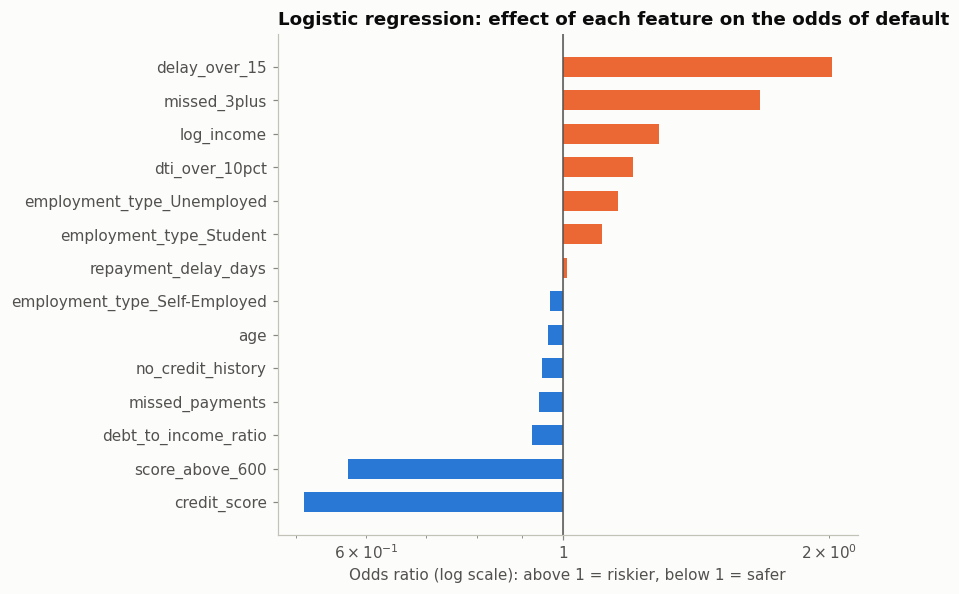

Intercept: -0.665


,coefficient,odds_ratio
delay_over_15,0.6994,2.0126
missed_3plus,0.5119,1.6684
log_income,0.2491,1.2829
dti_over_10pct,0.1824,1.2001
employment_type_Unemployed,0.1441,1.1550
employment_type_Student,0.1009,1.1061
repayment_delay_days,0.0117,1.0117
employment_type_Self-Employed,-0.0324,0.9681
age,-0.0389,0.9618
no_credit_history,-0.0528,0.9486


In [12]:
lr_model = log_reg.named_steps["model"]
coefs = pd.DataFrame({"coefficient": lr_model.coef_[0]}, index=feature_names)
coefs["odds_ratio"] = np.exp(coefs["coefficient"])
coefs = coefs.sort_values("odds_ratio")

fig, ax = plt.subplots(figsize=(8, 5.5))
colours = [ORANGE if v > 1 else BLUE for v in coefs["odds_ratio"]]
ax.barh(coefs.index, coefs["odds_ratio"] - 1, left=1, color=colours, height=0.6)
ax.axvline(1, color=INK_2, linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.2g"))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Odds ratio (log scale): above 1 = riskier, below 1 = safer")
ax.set_title("Logistic regression: effect of each feature on the odds of default")
plt.tight_layout()
plt.show()

print(f"Intercept: {lr_model.intercept_[0]:.3f}")
coefs.sort_values("odds_ratio", ascending=False)

**What we see** (odds ratios per one standard deviation, or for switching a 0/1 flag on):
- **Strongest risk drivers:** `delay_over_15` (×2.0) and `missed_3plus` (×1.7). Past repayment problems beyond the EDA thresholds strongly raise the odds of default.
- **Strongest protective factors:** `credit_score` (×0.51) and `score_above_600` (×0.57). A higher score cuts the odds of default sharply, with an extra drop above 600.
- **Employment** (compared with Salaried): Unemployed ×1.16 and Student ×1.11 are riskier; Self-Employed ×0.97 is about the same.
- **The raw versions** of the flagged features (`missed_payments`, `repayment_delay_days`, `debt_to_income_ratio`) now have odds ratios close to 1. Their flags have taken over most of their effect, which shows the effects really are thresholds rather than smooth slopes.
- **A warning sign:** `log_income` has an odds ratio of 1.28, which says higher income means *more* risk. That contradicts the EDA, where higher income clearly meant *less* risk. This is the **multicollinearity** effect from Section 5: income and credit score carry almost the same information, so the model uses credit score for the main effect and gives income a small correction in the opposite direction. **The predictions are still fine, but this coefficient should not be interpreted on its own.** For a production scorecard, a credit team would usually drop one of the two.

## 10. Model 2: Decision tree

#### What we're doing
Training a decision tree, using **grid search with cross-validation** to choose its two most important hyperparameters:

- **`max_depth`**: the maximum number of questions in a row from the top of the tree to a final answer. Deeper trees can capture more detail but overfit more easily. `None` means "no limit".
- **`min_samples_leaf`**: the minimum number of customers in each final group (a **leaf**). Larger values stop the tree from creating tiny groups based on a handful of customers, which is a common cause of overfitting.

Grid search tries all 7 × 4 = 28 combinations, each with 5-fold cross-validation (140 trees in total), and keeps the combination with the best average AUC.

#### How the code works
- `param_grid` lists the values to try. The `model__` prefix tells scikit-learn the setting belongs to the step called `"model"` inside our pipeline.
- `GridSearchCV(pipeline, param_grid, cv=cv, scoring="roc_auc")` runs the search. `n_jobs=-1` uses all your computer's processor cores to run faster.
- After `.fit(...)`, `tree_search.best_params_` holds the winning settings, `best_score_` its cross-validated AUC, and `best_estimator_` the final tree, retrained on the whole training set with those settings.
- `cv_results_` holds the scores of every combination. We show the top 5, to see how close the alternatives were.

In [13]:
tree_grid = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, None],
    "model__min_samples_leaf": [1, 20, 50, 100],
}
tree_search = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
                           tree_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
tree_search.fit(X_train, y_train)
decision_tree = tree_search.best_estimator_

print("Best settings:", tree_search.best_params_)
print(f"Cross-validated AUC: {tree_search.best_score_:.3f} "
      f"± {tree_search.cv_results_['std_test_score'][tree_search.best_index_]:.3f}")

(pd.DataFrame(tree_search.cv_results_)
   [["param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score", "std_test_score"]]
   .sort_values("mean_test_score", ascending=False).head(5)
   .rename(columns={"param_model__max_depth": "max_depth", "param_model__min_samples_leaf": "min_samples_leaf",
                    "mean_test_score": "CV AUC", "std_test_score": "CV AUC std"}))

Best settings: {'model__max_depth': 4, 'model__min_samples_leaf': 50}
Cross-validated AUC: 0.772 ± 0.011


,max_depth,min_samples_leaf,CV AUC,CV AUC std
10,4,50,0.7717,0.0107
18,6,50,0.7698,0.0110
14,5,50,0.7696,0.0098
6,3,50,0.7694,0.0090
9,4,20,0.7684,0.0103


**What we see:**
- The best tree has a **maximum depth of 4** and at least **50 customers per leaf**, with a cross-validated **AUC of 0.772**.
- The top 5 combinations are all within 0.003 of each other, so the exact settings matter little, as long as the leaves are reasonably large (`min_samples_leaf = 50` appears in 4 of the top 5).

### 10.1 What happens without limits? (overfitting demonstration)

#### What we're doing
To see overfitting with our own eyes, we train a tree with **no depth limit** and compare its training and test AUC with the tuned tree.

#### How the code works
`DecisionTreeClassifier()` with default settings grows until every leaf is "pure" (contains only defaulters or only non-defaulters), effectively memorising the training customers.

In [14]:
unlimited_tree = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False).fit(X_train, y_train)

overfit = pd.DataFrame({
    "Train AUC": [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in (unlimited_tree, decision_tree)],
    "Test AUC":  [roc_auc_score(y_test,  m.predict_proba(X_test)[:, 1])  for m in (unlimited_tree, decision_tree)],
    "Leaves":    [m.named_steps["model"].get_n_leaves() for m in (unlimited_tree, decision_tree)],
}, index=["Unlimited tree", "Tuned tree"])
overfit

,Train AUC,Test AUC,Leaves
Unlimited tree,1.0000,0.6191,1564
Tuned tree,0.7745,0.7676,15


**What we see:** a textbook case of **overfitting**.
- The unlimited tree has **1,564 leaves** and a **perfect training AUC of 1.000**: it has memorised every training customer. On new customers its AUC collapses to **0.619**.
- The tuned tree has only **15 leaves**. Its training (0.775) and test (0.768) AUCs are almost identical, so it learned real patterns rather than noise.

### 10.2 Drawing the tree

#### What we're doing
A decision tree's big advantage is that it can be drawn and read like a credit policy. We draw the **top 3 levels** of the tuned tree (the full tree is a bit too big to read comfortably).

**How to read each box:**
- **First line:** the question, e.g. `credit_score <= 600.5`. Go **left if true**, **right if false**. The values are in their **original units** (trees don't use scaling). For the 0/1 flags, `missed_3plus <= 0.5` simply means "is the flag 0?" (true → the customer has fewer than 3 missed payments).
- **`samples`:** the share of training customers reaching this box.
- **`value`:** the share of [repaid, defaulted] customers in the box.
- **`class`:** the majority outcome in the box.
- **Colour:** **orange = mostly repaid**, **blue = mostly defaulted**, white = mixed. Darker = more one-sided.
- Boxes marked `(...)` continue deeper; they are hidden to keep the drawing readable.

#### How the code works
`plot_tree(...)` draws the tree. `max_depth=3` limits the drawing (not the model). `proportion=True` shows shares instead of counts; `filled=True` adds the colours.

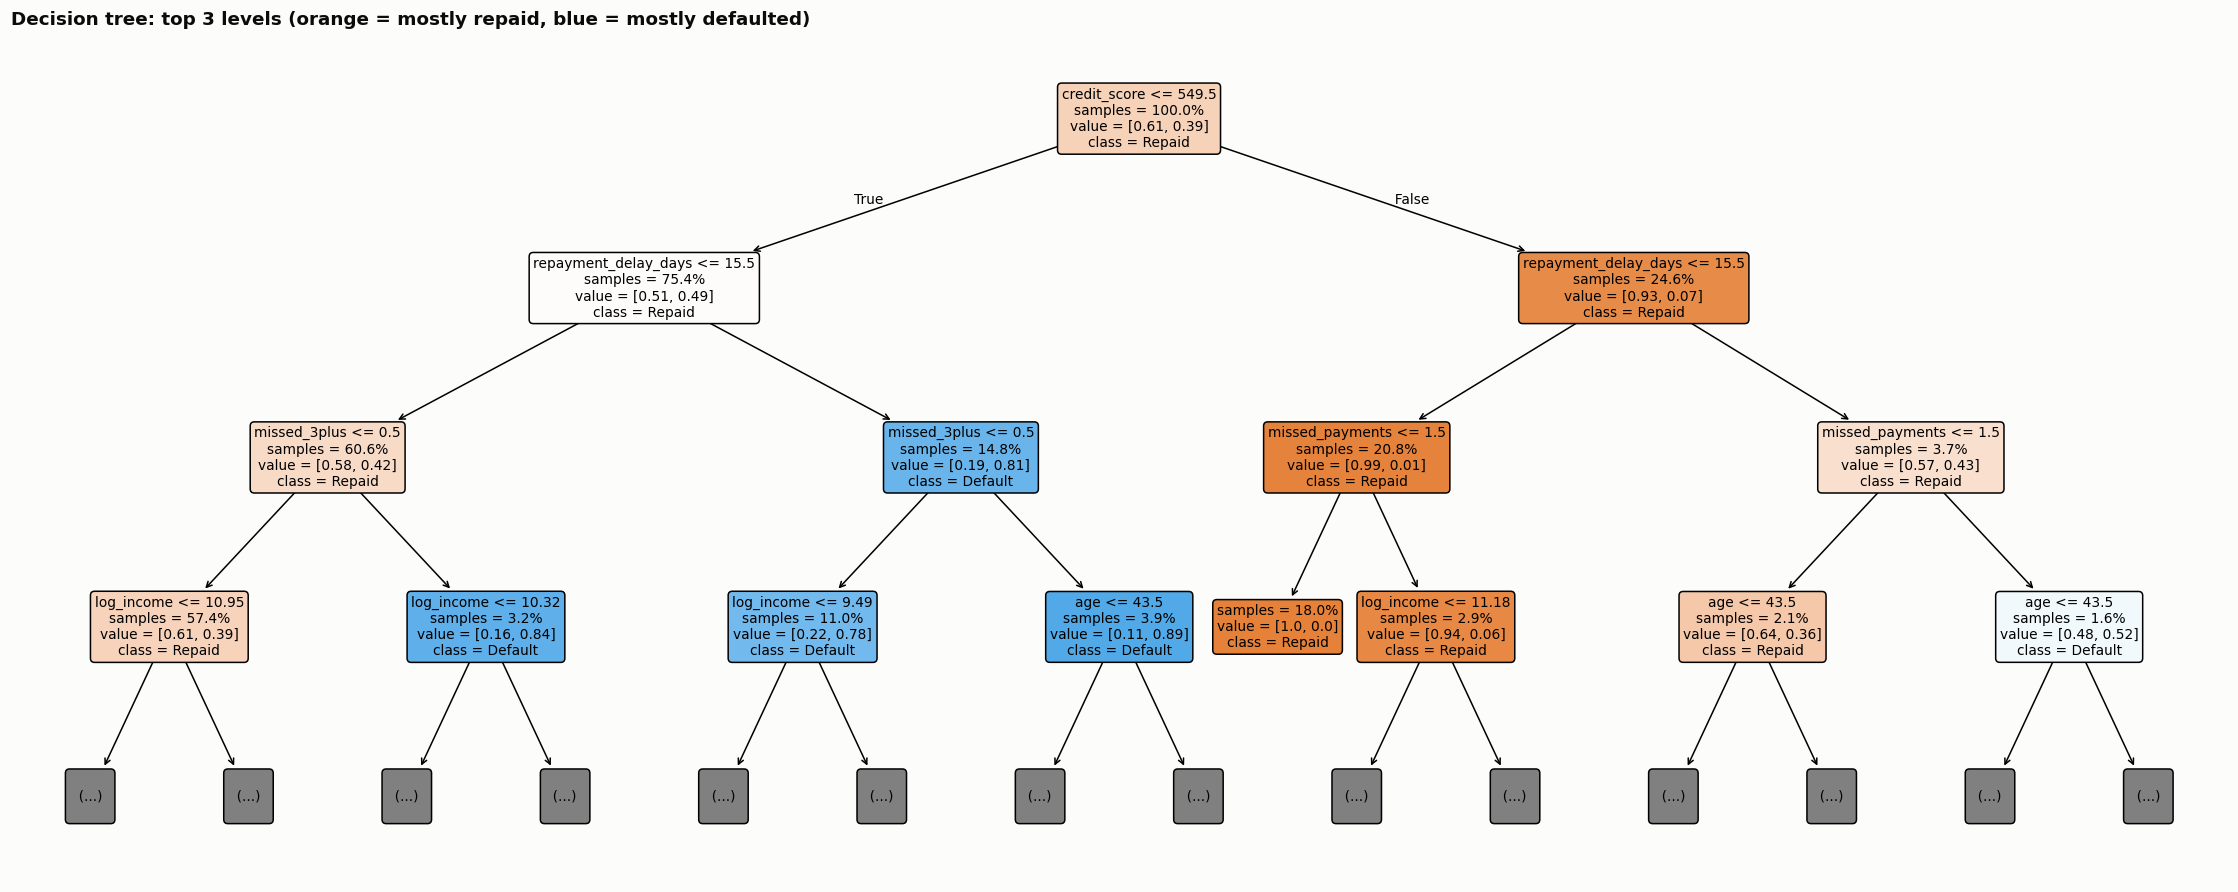

In [15]:
fig, ax = plt.subplots(figsize=(26, 10))
plot_tree(decision_tree.named_steps["model"], feature_names=feature_names, class_names=["Repaid", "Default"],
          max_depth=3, filled=True, proportion=True, rounded=True, fontsize=9, impurity=False, precision=2, ax=ax)
ax.set_title("Decision tree: top 3 levels (orange = mostly repaid, blue = mostly defaulted)")
plt.show()

**What we see:** the tree rediscovered the EDA findings on its own:
1. **First question: is the credit score 549 or below?** This is the single most useful split. 75% of customers are at or below it (49% default rate); the 25% above it have only a 7% default rate.
2. **Second question, on both sides: is the repayment delay more than 15 days?** This is the same threshold we found in the EDA.
3. **Then: 3 or more missed payments?** Low score + long delays + 3+ missed payments gives an **89% default rate**.
4. The safest group: score above 549, delay of 15 days or less, and at most 1 missed payment. That is **18% of customers with almost no defaults**.

`log_income` splits are in log units. To convert back, use e^value: for example, 10.95 ≈ an income of 57,000, and 9.49 ≈ 13,200.

## 11. Model 3: Random forest

#### What we're doing
Training a random forest, again tuning hyperparameters with grid search and 5-fold cross-validation:

- **`n_estimators`**: number of trees in the forest. More trees = more stable predictions, but slower. Beyond a few hundred, gains are usually tiny. We fix it at 300.
- **`max_depth`**: maximum depth of each tree.
- **`min_samples_leaf`**: minimum customers per leaf.
- **`max_features`**: how many features each split may choose from. `"sqrt"` = the square root of the number of model inputs (here about 3 of 14); `0.5` = half of them. Fewer features per split = more variety between trees = better "diversification".

3 × 3 × 2 = 18 combinations × 5 folds = 90 forests of 300 trees each. **This cell takes a little longer** (roughly 10–60 seconds, depending on your computer).

#### How the code works
Same pattern as the decision tree: define the grid, run `GridSearchCV`, keep the best estimator. `n_jobs=-1` in the forest itself also trains trees in parallel.

In [16]:
forest_grid = {
    "model__max_depth": [6, 10, None],
    "model__min_samples_leaf": [1, 10, 30],
    "model__max_features": ["sqrt", 0.5],
}
forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    forest_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
forest_search.fit(X_train, y_train)
random_forest = forest_search.best_estimator_

print("Best settings:", forest_search.best_params_)
print(f"Cross-validated AUC: {forest_search.best_score_:.3f} "
      f"± {forest_search.cv_results_['std_test_score'][forest_search.best_index_]:.3f}")

Best settings: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 30}
Cross-validated AUC: 0.771 ± 0.011


**What we see:** the best forest uses unlimited depth but at least **30 customers per leaf**, and half the features at each split. Its cross-validated **AUC is 0.771**, almost exactly the same as the single tree (0.772). Averaging 300 trees doesn't help here, probably because the patterns in this data are a few simple thresholds, which a single small tree already captures.

## 12. Evaluating all three models on the test set

Now, for the first time, we use the **test set**: 3,104 customers none of the models has seen.

### 12.1 All metrics in one table

#### What we're doing
Computing every metric from Section 0.7 for each model, at the default cut-off of 0.5. We also include:
- **Train AUC** next to **Test AUC**, to check for overfitting (a big gap is a warning sign).
- **CV AUC**, the cross-validated AUC from training, as a second, independent estimate.

#### How the code works
- `predict_proba(X_test)[:, 1]` gives each customer's predicted **probability of default**. (`predict_proba` returns two columns, P(repaid) and P(default); `[:, 1]` takes the second.)
- `(proba >= threshold).astype(int)` turns probabilities into 0/1 decisions at the cut-off.
- `evaluate(...)` computes every metric:
  - `confusion_matrix(...).ravel()` returns TN, FP, FN, TP, used for specificity.
  - `roc_curve(...)` returns the false positive rate and true positive rate at every possible cut-off; **KS** is the largest gap between them.
  - The other metrics come straight from scikit-learn functions with matching names.
- The results are collected in one table; `.T` flips it so models are columns.

In [17]:
MODELS = {
    "Logistic regression": log_reg,
    "Decision tree": decision_tree,
    "Random forest": random_forest,
}
CV_AUC = {
    "Logistic regression": lr_cv.mean(),
    "Decision tree": tree_search.best_score_,
    "Random forest": forest_search.best_score_,
}

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    fpr, tpr, _ = roc_curve(y_true, proba)
    auc = roc_auc_score(y_true, proba)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "Specificity": tn / (tn + fp),
        "F1 score": f1_score(y_true, pred),
        "ROC AUC": auc,
        "Gini": 2 * auc - 1,
        "KS statistic": (tpr - fpr).max(),
        "PR AUC": average_precision_score(y_true, proba),
        "Log loss": log_loss(y_true, proba),
        "Brier score": brier_score_loss(y_true, proba),
    }

test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in MODELS.items()}

results = {}
for name, model in MODELS.items():
    row = evaluate(y_test, test_proba[name])
    row["Train AUC"] = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    row["CV AUC"] = CV_AUC[name]
    results[name] = row

results = pd.DataFrame(results)
results["risk_score (benchmark)"] = np.nan
results.loc[["ROC AUC", "Gini"], "risk_score (benchmark)"] = [risk_score_auc, 2 * risk_score_auc - 1]
results.loc["Accuracy", "Naive (nobody defaults)"] = naive_accuracy
results.loc["ROC AUC", "Naive (nobody defaults)"] = 0.5
results.style.format("{:.3f}", na_rep="–")

,Logistic regression,Decision tree,Random forest,risk_score (benchmark),Naive (nobody defaults)
Accuracy,0.726,0.723,0.724,–,0.610
Balanced accuracy,0.669,0.665,0.667,–,–
Precision,0.788,0.779,0.778,–,–
Recall,0.408,0.404,0.408,–,–
Specificity,0.930,0.927,0.925,–,–
F1 score,0.537,0.532,0.536,–,–
ROC AUC,0.767,0.768,0.763,0.730,0.500
Gini,0.533,0.535,0.526,0.459,–
KS statistic,0.345,0.337,0.348,–,–
PR AUC,0.685,0.638,0.684,–,–


**What we see:**
- **The three models perform almost identically.** Test AUC is 0.763–0.768, Gini 0.53, and KS 0.34–0.35. All three clearly beat both benchmarks: accuracy 72–73% against 61% for the naive model, and AUC ~0.77 against 0.730 for `risk_score`.
- **At the 0.5 cut-off, precision is high (~78%) but recall is low (~41%).** When the models flag someone, they're usually right, but they **miss about 59% of defaulters**. Specificity is 93%: very few good customers are declined. The 0.5 cut-off is too lenient for a lender who cares about losses. Section 13 explores better cut-offs.
- **PR AUC:** logistic regression (0.685) and the random forest (0.684) beat the decision tree (0.638). The tree can only output 15 different probabilities, so it ranks customers more coarsely.
- **Log loss and Brier score:** all three are similar, with the trees slightly better, meaning their probabilities are marginally more accurate on average.
- **Overfitting check:**
  - Logistic regression (train 0.768, test 0.767) and the decision tree (0.774 vs 0.768) show almost no gap.
  - The random forest has a large gap (**train 0.879, test 0.763**): it has partly memorised the training data, although its test performance still matches the others.
- **CV AUC and test AUC agree closely** for every model. This confirms the test results are reliable, not a lucky split.

### 12.2 Confusion matrices

#### What we're doing
Showing the four boxes (Section 0.6) for each model at the 0.5 cut-off, as **counts** of test customers. This makes the precision/recall numbers concrete: you can see exactly how many bad customers each model would approve (**false negatives**, bottom-left) and how many good customers it would decline (**false positives**, top-right).

#### How the code works
- `confusion_matrix(y_test, pred)` returns a 2 × 2 grid of counts: rows are the actual outcome, columns the prediction.
- `imshow` draws the grid; the loop writes the count and its share of all test customers in each box.

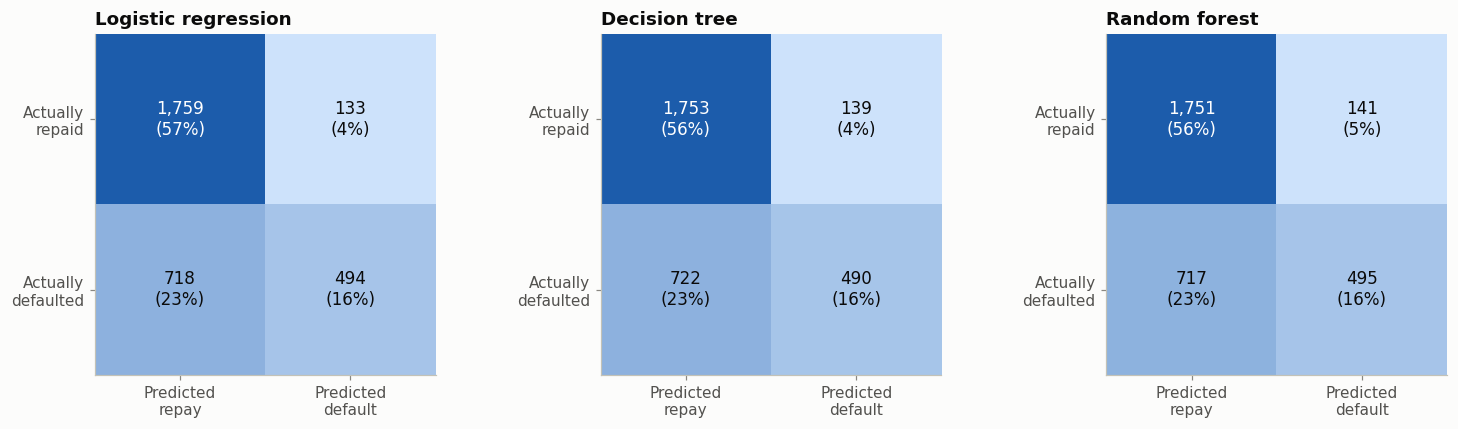

=== Logistic regression ===
              precision    recall  f1-score   support

      Repaid      0.710     0.930     0.805      1892
     Default      0.788     0.408     0.537      1212

    accuracy                          0.726      3104
   macro avg      0.749     0.669     0.671      3104
weighted avg      0.740     0.726     0.701      3104

=== Decision tree ===
              precision    recall  f1-score   support

      Repaid      0.708     0.927     0.803      1892
     Default      0.779     0.404     0.532      1212

    accuracy                          0.723      3104
   macro avg      0.744     0.665     0.668      3104
weighted avg      0.736     0.723     0.697      3104

=== Random forest ===
              precision    recall  f1-score   support

      Repaid      0.709     0.925     0.803      1892
     Default      0.778     0.408     0.536      1212

    accuracy                          0.724      3104
   macro avg      0.744     0.667     0.669      3104
we

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, proba) in zip(axes, test_proba.items()):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    ax.imshow(cm, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#cde2fb", "#1c5cab"]))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.0%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=11)
    ax.set_xticks([0, 1], ["Predicted\nrepay", "Predicted\ndefault"])
    ax.set_yticks([0, 1], ["Actually\nrepaid", "Actually\ndefaulted"])
    ax.grid(False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, proba in test_proba.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=["Repaid", "Default"], digits=3))

**What we see** (logistic regression; the other two are within a handful of customers):
- **1,759 good customers correctly approved** and **494 defaulters correctly declined**.
- **133 good customers wrongly declined** (false positives), only 4% of test customers.
- **718 defaulters wrongly approved** (false negatives), 23% of test customers. **This is the biggest problem at the 0.5 cut-off**: most defaulters get through.

**How to read the classification report:** one row per class. For the "Default" row, precision and recall are exactly as defined in Section 0.7. The "Repaid" row gives the same metrics from the good customers' point of view (its recall is the specificity). **Support** is the number of test customers in each class. **Macro avg** is the simple average of the two rows; **weighted avg** weights them by support.

### 12.3 ROC curves

#### What we're doing
The **ROC curve** (Receiver Operating Characteristic) shows the trade-off between catching defaulters and wrongly declining good customers, **across every possible cut-off**:
- **Vertical axis: true positive rate** (recall): the share of defaulters caught.
- **Horizontal axis: false positive rate** (1 − specificity): the share of good customers wrongly declined.
- Moving the cut-off from 1 down to 0 traces the curve from the bottom-left (decline nobody) to the top-right (decline everybody).
- A perfect model goes straight up to the top-left corner (catch every defaulter, decline no good customer). The **dashed diagonal** is random guessing.
- **AUC** is the area under the curve: the closer the curve hugs the top-left, the bigger the area.

#### How the code works
`roc_curve(y_test, proba)` returns the false and true positive rates at every cut-off; we draw one line per model and add the `risk_score` benchmark as a grey line.

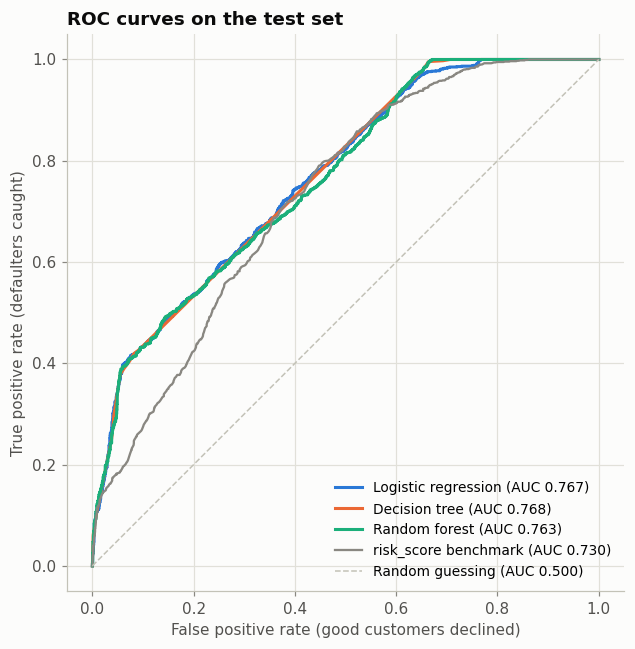

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, proba in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=MODEL_COLOURS[name], label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
fpr, tpr, _ = roc_curve(y_test, risk_score_test)
ax.plot(fpr, tpr, color=MUTED, linewidth=1.5, label=f"risk_score benchmark (AUC {risk_score_auc:.3f})")
ax.plot([0, 1], [0, 1], color=AXIS, linestyle="--", linewidth=1, label="Random guessing (AUC 0.500)")
ax.set_xlabel("False positive rate (good customers declined)")
ax.set_ylabel("True positive rate (defaulters caught)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**What we see:**
- The three model curves lie **almost on top of each other**.
- All three are clearly above the `risk_score` benchmark, especially on the **left side** of the chart, which matters most in practice. If we're only willing to decline 5% of good customers, the models catch about **35% of defaulters**, against about **18%** for `risk_score`.
- The steep rise at the start shows the models are very good at identifying the **clearly risky** customers. The flatter middle shows they struggle to separate the large group of "average" customers (more on this in Section 14).

### 12.4 Precision-recall curves

#### What we're doing
The **precision-recall curve** focuses on the defaulters only: as we lower the cut-off to catch more defaulters (higher recall, moving right), how quickly does precision drop (more good customers among those we flag)?
- The **dashed horizontal line** is the default rate (~39%): a random model's precision.
- A curve that stays high for longer is better.

#### How the code works
`precision_recall_curve(y_test, proba)` returns precision and recall at every cut-off.

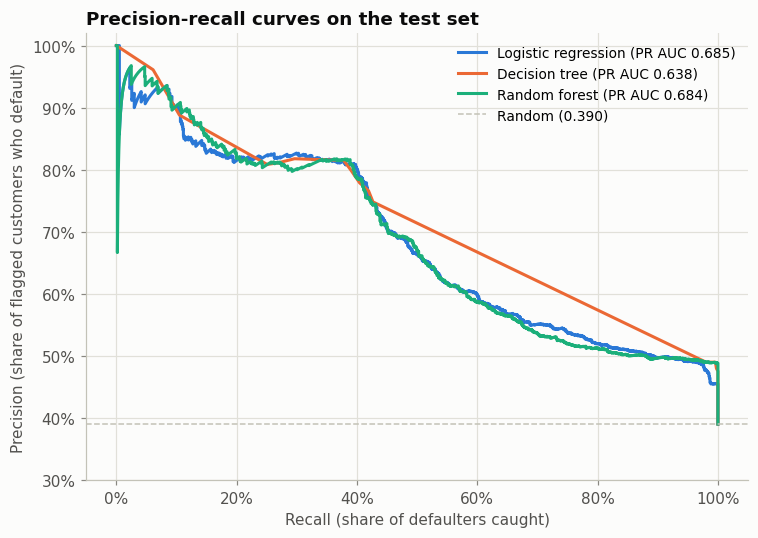

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in test_proba.items():
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ax.plot(recall, precision, color=MODEL_COLOURS[name],
            label=f"{name} (PR AUC {average_precision_score(y_test, proba):.3f})")
ax.axhline(y_test.mean(), color=AXIS, linestyle="--", linewidth=1, label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall (share of defaulters caught)")
ax.set_ylabel("Precision (share of flagged customers who default)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0.3, 1.02)
ax.set_title("Precision-recall curves on the test set")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

**What we see:**
- Up to about **40% recall**, precision stays around **80% or higher**: the riskiest customers are identified reliably.
- Beyond 40% recall, precision falls quickly. To catch more defaulters, we have to start declining many good customers too.
- The decision tree's curve has **straight segments**, because it only has 15 distinct probabilities to choose cut-offs from.

### 12.5 Calibration: are the probabilities realistic?

#### What we're doing
A model is **well calibrated** if its probabilities can be taken at face value: among all customers it gives a 30% default probability, about 30% should actually default. This matters whenever the probability is used directly, e.g. for **pricing** or **expected loss** provisions.

The **calibration curve** groups test customers into 10 bins by predicted probability, then plots the average **predicted** probability (horizontal) against the **actual** default rate (vertical) in each bin. A perfectly calibrated model lies on the **dashed diagonal**:
- **Above the diagonal:** the model **underestimates** risk.
- **Below the diagonal:** the model **overestimates** risk.

#### How the code works
`calibration_curve(y_test, proba, n_bins=10, strategy="quantile")` makes 10 bins with equal numbers of customers and returns the actual and predicted rates per bin.

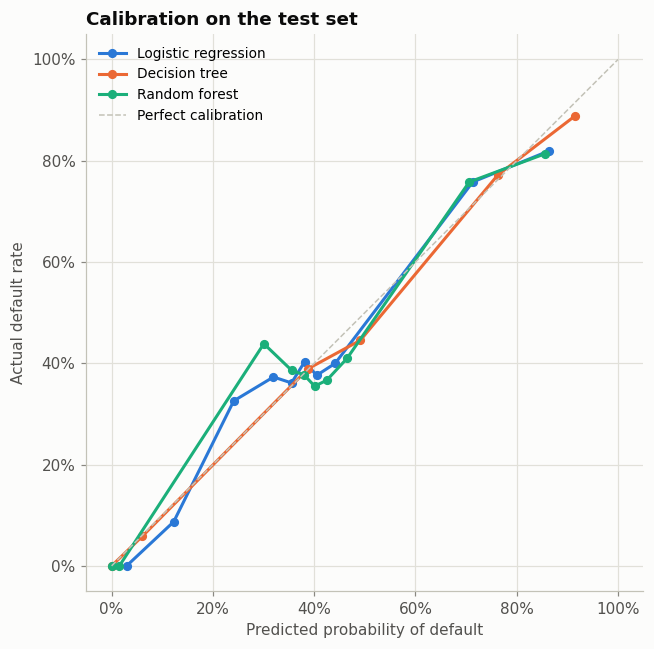

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, proba in test_proba.items():
    actual, predicted = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, marker="o", markersize=5, color=MODEL_COLOURS[name], label=name)
ax.plot([0, 1], [0, 1], color=AXIS, linestyle="--", linewidth=1, label="Perfect calibration")
ax.set_xlabel("Predicted probability of default")
ax.set_ylabel("Actual default rate")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Calibration on the test set")
ax.legend(loc="upper left", fontsize=9)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**What we see:** all three models are **reasonably well calibrated**, with points close to the diagonal across the range. When a model says "80% chance of default", about 80% of those customers really default. This means the predicted probabilities can be used directly, for example for expected-loss estimates. Most customers sit in the 30–45% range, where the curves wobble slightly around the diagonal.

## 13. Choosing the cut-off (approve / decline threshold)

#### What we're doing
So far we used a cut-off of 0.5: decline if the predicted default probability is 50% or more. But **0.5 is not special**; it's a business decision. A lower cut-off declines more customers: fewer losses, but less business. A higher cut-off approves more customers: more business, but more losses.

**Which model?** We compare models by **cross-validated AUC**, not test AUC: choosing based on the test set would make the test results look slightly better than they really are. The code below prints each model's CV AUC with its standard deviation. If the differences are **smaller than the standard deviation**, the models are effectively **tied**: the gap could easily be random noise.

When models are tied, credit teams prefer the **simplest and most explainable** one. Here that's **logistic regression**: every feature has a clear odds ratio, it converts directly into a points-based scorecard, and it produces a smooth ranking (thousands of distinct probabilities, against only 15 for the tuned decision tree, which can only output one probability per leaf).

Then, for several cut-offs, we show what would happen to the test customers if we used the chosen model:

| Column | Meaning |
|---|---|
| **Approval rate** | Share of applicants approved |
| **Default rate among approved** | The bad rate of the approved book. This is what drives credit losses. |
| **Defaulters caught** | Recall: share of all defaulters that were declined |
| **Good customers declined** | False positive rate: share of good customers turned away (lost revenue) |
| **Precision** | Of those declined, share that would really have defaulted |
| **F1** | Balance of precision and recall |

Without a model, approving everyone gives a 39% default rate. The table shows how much a model can reduce that, and at what cost in approvals.

#### How the code works
- The first lines print CV AUC ± standard deviation per model and the gap between the best and worst.
- `chosen_name` is set to logistic regression, following the reasoning above.
- For each cut-off, `approved = proba < t` marks customers whose probability is below the cut-off. `y_test[approved].mean()` is the default rate among them.

In [22]:
CV_STD = {
    "Logistic regression": lr_cv.std(),
    "Decision tree": tree_search.cv_results_["std_test_score"][tree_search.best_index_],
    "Random forest": forest_search.cv_results_["std_test_score"][forest_search.best_index_],
}
for name in MODELS:
    print(f"{name:20s} CV AUC {CV_AUC[name]:.3f} ± {CV_STD[name]:.3f}")
gap = max(CV_AUC.values()) - min(CV_AUC.values())
print(f"\nGap between best and worst: {gap:.3f} (typical standard deviation: {np.mean(list(CV_STD.values())):.3f})")
print("Distinct predicted probabilities on the test set:",
      {name: len(np.unique(p.round(6))) for name, p in test_proba.items()})

chosen_name = "Logistic regression"
best_name = chosen_name
best_proba = test_proba[chosen_name]
print(f"\nChosen model: {chosen_name}\n")

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    approved = best_proba < t
    pred = (~approved).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "Cut-off": t,
        "Approval rate": approved.mean(),
        "Default rate among approved": y_test[approved].mean(),
        "Defaulters caught": tp / (tp + fn),
        "Good customers declined": fp / (fp + tn),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })
threshold_table = pd.DataFrame(rows).set_index("Cut-off")
threshold_table.style.format("{:.1%}").format_index("{:.1f}")

Logistic regression  CV AUC 0.765 ± 0.011
Decision tree        CV AUC 0.772 ± 0.011
Random forest        CV AUC 0.771 ± 0.011

Gap between best and worst: 0.006 (typical standard deviation: 0.011)
Distinct predicted probabilities on the test set: {'Logistic regression': 3091, 'Decision tree': 15, 'Random forest': 2891}

Chosen model: Logistic regression



,Approval rate,Default rate among approved,Defaulters caught,Good customers declined,Precision,F1
Cut-off,,,,,,
0.2,20.1%,4.3%,97.8%,68.4%,47.8%,64.2%
0.3,31.1%,14.5%,88.4%,56.3%,50.1%,64.0%
0.4,63.2%,26.5%,57.2%,23.7%,60.7%,58.9%
0.5,79.8%,29.0%,40.8%,7.0%,78.8%,53.7%
0.6,81.2%,29.3%,39.0%,5.9%,80.9%,52.6%
0.7,83.6%,30.7%,34.3%,5.0%,81.6%,48.3%


**What we see:**
- **Choosing the model:** the cross-validated AUCs differ by only **0.006**, less than the typical standard deviation (0.011), so the three models are statistically tied. We choose **logistic regression** for explainability and smooth ranking: it produces 3,091 distinct probabilities on the test set, against only 15 for the decision tree.
- **Reading the cut-off table:**
  - **Cut-off 0.5** (the default): approves 80% of applicants, but the approved book still has a **29% default rate**, and only 41% of defaulters are caught.
  - **Cut-off 0.4:** approves 63%, default rate among approved falls to **26.5%**, and 57% of defaulters are caught. But 24% of good customers are turned away.
  - **Cut-off 0.3:** approves only 31%, but the approved book's default rate falls to **14.5%**.
  - **Cut-off 0.2:** approves the safest 20%, with a default rate of just **4.3%**.
- **There is no "correct" cut-off.** It depends on the business: profit per good customer, loss per default, and growth targets. A lender with high margins might accept a 0.5 cut-off; a cautious lender might choose 0.3.
- **The big jump between 0.3 and 0.4:** approvals go from 31% to 63%. A large group of customers has predicted probabilities between 30% and 40%, and the model can't separate them well. Section 14 shows this clearly.

## 14. Gains table: ranking customers into risk groups

#### What we're doing
The **gains table** (or **decile table**) is the standard way credit teams present a scoring model. It answers: *"If we rank applicants by predicted risk, how concentrated are the defaulters at the top?"*

1. Sort test customers from **highest to lowest** predicted risk.
2. Split them into 10 equal groups (**deciles**). Decile 1 = the riskiest 10%.
3. For each decile, report:

| Column | Meaning |
|---|---|
| **Min / max probability** | Range of predicted default probability in the decile |
| **Default rate** | Actual default rate in the decile. A good model shows a steady fall from decile 1 to 10. |
| **Cumulative % of defaulters** | Share of all defaulters found in this and all riskier deciles |
| **Lift** | Default rate in the decile ÷ overall default rate. Lift 2 = twice as risky as average. |

Example of how a credit team uses this: "Declining the riskiest 30% of applicants removes X% of all defaulters."

#### How the code works
- `pd.qcut(-best_proba, 10, labels=...)` splits customers into 10 equal groups by predicted probability. The minus sign makes decile 1 the **riskiest**. `rank(method="first")` breaks ties so every decile has the same size.
- `groupby("decile")` then computes the statistics per decile; `.cumsum()` gives running totals.

In [23]:
gains = pd.DataFrame({"proba": best_proba, "default": y_test.values})
gains["decile"] = pd.qcut((-gains["proba"]).rank(method="first"), 10, labels=range(1, 11))

g = gains.groupby("decile", observed=True).agg(
    customers=("default", "size"), defaulters=("default", "sum"),
    min_prob=("proba", "min"), max_prob=("proba", "max"))
g["default_rate"] = g["defaulters"] / g["customers"]
g["cum_pct_defaulters"] = g["defaulters"].cumsum() / g["defaulters"].sum()
g["lift"] = g["default_rate"] / y_test.mean()

print(f"Gains table for: {best_name}")
g.style.format({"min_prob": "{:.1%}", "max_prob": "{:.1%}", "default_rate": "{:.1%}",
                "cum_pct_defaulters": "{:.1%}", "lift": "{:.2f}"})

Gains table for: Logistic regression


,customers,defaulters,min_prob,max_prob,default_rate,cum_pct_defaulters,lift
decile,,,,,,,
1,311,255,79.1%,97.1%,82.0%,21.0%,2.10
2,310,235,56.4%,79.1%,75.8%,40.4%,1.94
3,310,124,41.8%,56.1%,40.0%,50.7%,1.02
4,311,117,39.3%,41.8%,37.6%,60.3%,0.96
5,310,125,36.8%,39.3%,40.3%,70.6%,1.03
6,310,112,34.1%,36.8%,36.1%,79.9%,0.93
7,311,116,29.3%,34.1%,37.3%,89.4%,0.96
8,310,101,19.9%,29.3%,32.6%,97.8%,0.83
9,310,27,3.9%,19.9%,8.7%,100.0%,0.22


**What we see:**
- **The riskiest 20% of customers (deciles 1–2) default at 76–82%,** about twice the average (lift ~2). Declining just these two deciles would remove **40% of all defaulters**.
- **The safest 20% (deciles 9–10) default at 0–9%.** These are the clear "approve" customers.
- **Deciles 3–8, the middle 60%, all default at 33–40%,** close to the overall average (lift ~1). The model can't tell these customers apart.

That middle group is the **main limitation of this dataset**, not of the models. All three models hit the same ceiling (AUC ~0.77). The available features (credit score, repayment history, income, employment) don't contain enough information to separate this group. Improving the model would need **new data**, such as bank transaction history, BNPL purchase history or bureau details, rather than a more complex algorithm.

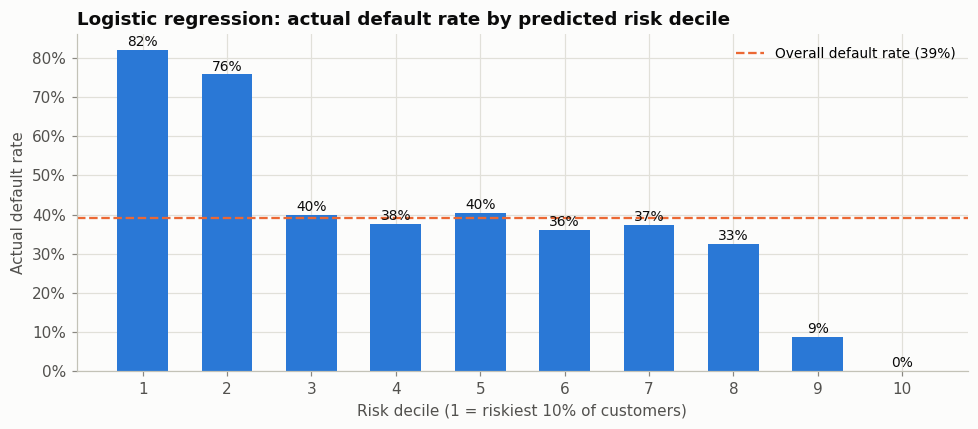

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(g.index.astype(str), g["default_rate"], color=BLUE, width=0.6)
ax.axhline(y_test.mean(), color=ORANGE, linestyle="--", linewidth=1.5, label=f"Overall default rate ({y_test.mean():.0%})")
for i, v in enumerate(g["default_rate"]):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Risk decile (1 = riskiest 10% of customers)")
ax.set_ylabel("Actual default rate")
ax.set_title(f"{best_name}: actual default rate by predicted risk decile")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 15. Which features matter most?

#### What we're doing
Comparing feature importance across all three models with one common method: **permutation importance**.

**The idea:** take one feature in the test set and **shuffle** its values randomly between customers, which destroys its link to default while keeping everything else the same. Then measure how much the model's AUC drops.
- A **big drop** = the model relies heavily on this feature.
- **No drop** = the model doesn't need it.

We repeat the shuffle 10 times per feature and average, because a single shuffle is random. Using the same method for all three models makes them directly comparable (each model type also has its own built-in importance measure, but they're on different scales).

Note: when two features carry the same information (like credit score and log income), shuffling one of them causes only a small drop, because the model can lean on the other. So permutation importance can **understate** overlapping features.

#### How the code works
- `permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, ...)` does the shuffling and scoring. Because our models are pipelines, it shuffles the **original** columns (before scaling/encoding), so `employment_type` is treated as one feature.
- `.importances_mean` holds the average AUC drop per feature.
- **This cell takes a little while** (the random forest is scored 130 times).

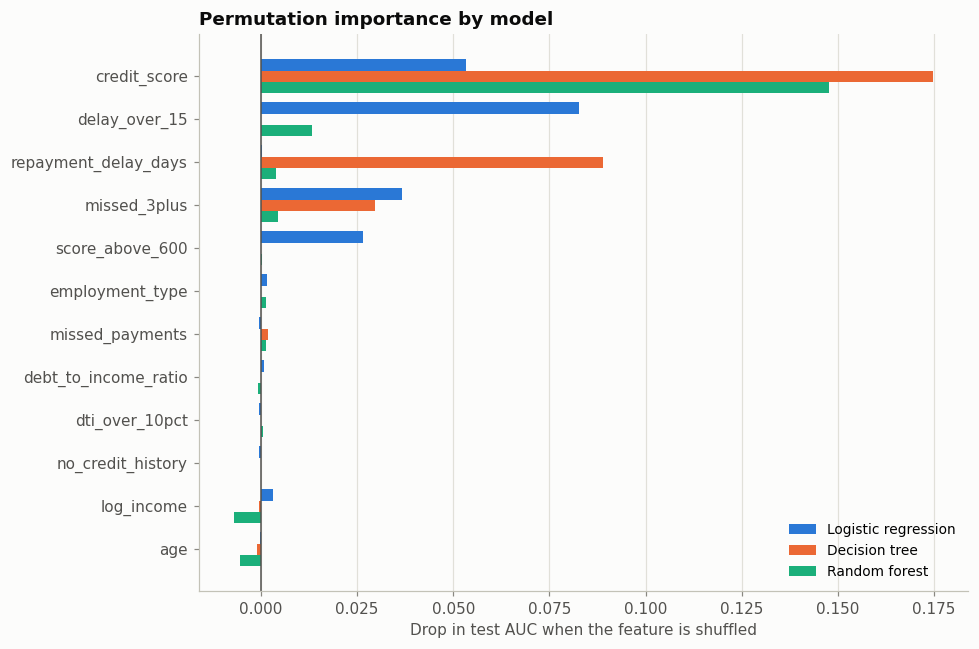

,Logistic regression,Decision tree,Random forest
credit_score,0.0534,0.1748,0.1477
delay_over_15,0.0827,0.0000,0.0133
missed_3plus,0.0368,0.0297,0.0045
repayment_delay_days,0.0002,0.0889,0.0040
missed_payments,-0.0006,0.0019,0.0014
employment_type,0.0017,0.0000,0.0013
dti_over_10pct,-0.0005,0.0000,0.0004
score_above_600,0.0265,0.0000,0.0002
no_credit_history,-0.0005,0.0000,-0.0001
debt_to_income_ratio,0.0008,0.0000,-0.0009


In [25]:
importance = {}
for name, model in MODELS.items():
    r = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                               random_state=RANDOM_STATE, n_jobs=-1)
    importance[name] = pd.Series(r.importances_mean, index=FEATURES)
importance = pd.DataFrame(importance)
importance = importance.loc[importance.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(importance))
height = 0.26
for k, name in enumerate(MODELS):
    ax.barh(y_pos + (1 - k) * height, importance[name], height=height, color=MODEL_COLOURS[name], label=name)
ax.set_yticks(y_pos, importance.index)
ax.axvline(0, color=INK_2, linewidth=1)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Drop in test AUC when the feature is shuffled")
ax.set_title("Permutation importance by model")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

importance.sort_values("Random forest", ascending=False).round(4)

**What we see:**
- **Credit score is the most important feature for every model.** The trees rely on it most heavily: shuffling it drops their AUC by 0.15–0.17.
- **The models use the same information in different forms:**
  - Logistic regression relies on the **flags** (`delay_over_15`, `missed_3plus`, `score_above_600`), because those capture the cliffs it can't model on its own.
  - The decision tree uses the **raw** `repayment_delay_days` and finds the 15-day threshold itself.
- **Employment, DTI, age and income contribute almost nothing** once credit score and repayment history are known. For the random forest, shuffling `age` and `log_income` slightly *improves* the AUC (negative bars), meaning they only add noise. This matches the EDA (age IV 0.03) and the income–credit-score overlap.
- **A simpler model with just credit score and repayment history would probably perform almost as well.** That's a good next experiment.

## 16. Summary and conclusions

### What we built
- **Features:** 7 of the original columns, chosen from the EDA, plus **log income** and **five threshold flags** engineered at the cliffs found in the EDA. Nine columns were dropped as identifiers, derived formulas, capped, or unrelated to default.
- **Models:** logistic regression, a decision tree (depth 4, tuned) and a random forest (300 trees, tuned), each tuned with 5-fold cross-validation on 70% of the data, and evaluated once on the remaining 30%.

### Results on the test set (3,104 customers)

| | Logistic regression | Decision tree | Random forest | `risk_score` benchmark |
|---|---|---|---|---|
| ROC AUC | 0.767 | 0.768 | 0.763 | 0.730 |
| Gini | 0.533 | 0.535 | 0.526 | 0.459 |
| KS | 0.345 | 0.337 | 0.348 | – |
| Accuracy (0.5 cut-off) | 72.6% | 72.3% | 72.4% | – (naive: 61.0%) |
| Precision / Recall (0.5) | 78.8% / 40.8% | 77.9% / 40.4% | 77.8% / 40.8% | – |

### Key conclusions
1. **All three models perform about the same** (AUC ~0.77, Gini ~0.53) and clearly beat the existing `risk_score` (Gini 0.46). A Gini above 0.5 is respectable for an application scorecard.
2. **Feature engineering mattered more than the choice of algorithm.** Adding the EDA threshold flags lifted logistic regression's AUC from 0.737 to 0.765. Switching to a random forest added nothing.
3. **Logistic regression is the recommended model.** It ties on performance, has no overfitting, gives smooth risk rankings, and every feature effect is explainable as an odds ratio, which is what lenders and regulators need.
4. **The 0.5 cut-off is too lenient.** It misses ~59% of defaulters. The cut-off should be set from business economics (Section 13); for example, 0.4 catches 57% of defaulters while approving 63% of applicants.
5. **The models separate the extremes well but not the middle.** The riskiest 20% default at ~79% and the safest 20% at ~4%, while the middle 60% are indistinguishable at ~33–40%. More data, not more complex models, is needed to improve further.
6. **Credit score and past repayment behaviour drive almost all predictions.** Employment, income, DTI and age add little once those are known.

### Limitations
- The dataset appears **synthetic** (very high 39% default rate, evenly spread categories), so the results may not transfer to a real BNPL portfolio.
- **`missed_payments` and `repayment_delay_days` are assumed to describe past history.** If they actually describe the current loan, they would be leakage and the true performance would be lower (see the EDA notebook, Section 6.5).
- **Income and credit score overlap heavily**, so their individual logistic regression coefficients shouldn't be interpreted on their own.
- The split is random. With real data, a **time-based** split (train on older loans, test on newer ones) would be a more realistic test.

### Possible next steps
1. **Simplify:** retrain logistic regression with only credit score, repayment history and their flags, and check whether performance holds.
2. **Build a points-based scorecard** from the logistic regression, e.g. 600 points = 50:50 odds, +20 points doubles the odds of repaying.
3. **Set the cut-off from business numbers:** expected profit = (good customers approved × margin) − (defaulters approved × loss per default).
4. **Try WoE (Weight of Evidence) encoding** of banded features, the classic credit scorecard approach.